In [5]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.patches import Patch
import seaborn as sns
import scanpy as sc

from pydeseq2.dds import DeseqDataSet
from pydeseq2.ds  import DeseqStats

import math

import os


data_dir = str(os.getcwd())


In [6]:
MIN_TOTAL_COUNTS = 50

LFC_THRESH       = 2.0

SAMPLE_REGION = {
    "V7": "MEC", "V8": "MEC", "V9": "MEC",
    "V1": "IntEC", "V2": "IntEC", "V3": "IntEC",
    "V4": "LEC",   "V5": "LEC",  "V6": "LEC",
}
SAMPLE_IDS = ["V1","V2","V3","V4","V5","V6","V7","V8","V9"]
REGION_SAMPLE_IDS = {"MEC":["V7","V8","V9"], "IntEC":["V1","V2","V3"], "LEC":["V4","V5","V6"]}
REGION_COLORS = {"MEC":"#c74ba6", "IntEC":"#78c26b", "LEC":"#4bb1d1"}

SAMPLE_ANIMAL = {
    "V1": "animal1", "V4": "animal1", "V7": "animal1",
    "V2": "animal2", "V5": "animal2", "V8": "animal2",
    "V3": "animal3", "V6": "animal3", "V9": "animal3",
}

GRADIENT_THRESH = 0.35


EXAMPLE_GENES = {
    "Cplx3",
    "Prph",
    "Plxnd1",
    "Nectin3",
    "Hc",
    "Gm19026",
    "Kcnk2",
    "Cyp26b1",
}


In [7]:
raw_bulk_df = pd.read_csv(f"{data_dir}/input_data/ec_bulk_counts_filtered.csv")
raw_bulk_df.rename(columns = {raw_bulk_df.columns[0]: "gene_id"}, inplace=True)
raw_bulk_df = raw_bulk_df.set_index("gene_id")

gene_names = raw_bulk_df["gene_name"].copy()
count_matrix = raw_bulk_df[SAMPLE_IDS].astype(int)

keep_mask = count_matrix.sum(axis=1) >= MIN_TOTAL_COUNTS
count_matrix = count_matrix[keep_mask]
gene_names = gene_names[keep_mask]

print(f"Loaded {len(raw_bulk_df):,} genes. Kept {len(count_matrix):,} after filter (>={MIN_TOTAL_COUNTS} total counts).")

Loaded 22,693 genes. Kept 22,596 after filter (>=50 total counts).


# Fit DESeq2 model

In [8]:
sample_metadata = pd.DataFrame(
    {
        "region": [SAMPLE_REGION[s] for s in SAMPLE_IDS],
        "animal": [SAMPLE_ANIMAL[s] for s in SAMPLE_IDS],
    },
    index=SAMPLE_IDS
)

deseq_dataset = DeseqDataSet(
    counts = count_matrix.T,
    metadata = sample_metadata,
    design = '~ animal + region'
)

deseq_dataset.deseq2()

Using None as control genes, passed at DeseqDataSet initialization


Fitting size factors...
... done in 0.01 seconds.

Fitting dispersions...
... done in 0.75 seconds.

Fitting dispersion trend curve...
... done in 0.18 seconds.

Fitting MAP dispersions...
... done in 0.86 seconds.

Fitting LFCs...
... done in 0.85 seconds.

Calculating cook's distance...
... done in 0.01 seconds.

Replacing 0 outlier genes.



# Pairwise conparison of regions

In [5]:
def run_contrast(deseq_dataset, numerator_region, denominator_region, contrast_label):
    print(f"{numerator_region} vs {denominator_region}:")
    deseq_stats = DeseqStats(deseq_dataset, contrast=["region", numerator_region, denominator_region], alpha=0.05)
    deseq_stats.summary()
    
    return deseq_stats.results_df[["log2FoldChange","padj"]].rename(columns={
        "log2FoldChange": f"lfc_{contrast_label}",
        "padj": f"padj_{contrast_label}",
    })

intec_vs_mec = run_contrast(deseq_dataset, "IntEC", "MEC", "intECvMEC")
intec_vs_lec = run_contrast(deseq_dataset, "IntEC", "LEC", "intECvLEC")
lec_vs_mec = run_contrast(deseq_dataset, "LEC", "MEC", "LECvMEC")

Running Wald tests...


IntEC vs MEC:


... done in 0.44 seconds.

Running Wald tests...


Log2 fold change & Wald test p-value: region IntEC vs MEC
                       baseMean  log2FoldChange     lfcSE      stat    pvalue  \
gene_id                                                                         
ENSMUSG00000000001  3861.870585       -0.087949  0.163045 -0.539417  0.589599   
ENSMUSG00000000028   348.800512       -0.118426  0.346004 -0.342269  0.732149   
ENSMUSG00000000037    16.610068        3.722242  1.802229  2.065355  0.038889   
ENSMUSG00000000049    23.401595        0.902805  1.103820  0.817891  0.413419   
ENSMUSG00000000056  6536.903042       -0.078870  0.201709 -0.391011  0.695789   
...                         ...             ...       ...       ...       ...   
ENSMUSG00002076932   106.641071       -0.046906  0.401837 -0.116729  0.907075   
ENSMUSG00002076967    52.372550       -0.442369  1.521033 -0.290834  0.771178   
ENSMUSG00002076982     6.224694       -1.493292  3.274633 -0.456018  0.648377   
ENSMUSG00002076984    10.594774       -1.051185  1.

... done in 0.46 seconds.

Running Wald tests...


Log2 fold change & Wald test p-value: region IntEC vs LEC
                       baseMean  log2FoldChange     lfcSE      stat    pvalue  \
gene_id                                                                         
ENSMUSG00000000001  3861.870585       -0.026362  0.163106 -0.161626  0.871600   
ENSMUSG00000000028   348.800512        0.117979  0.346691  0.340300  0.733630   
ENSMUSG00000000037    16.610068        1.386754  1.734556  0.799486  0.424008   
ENSMUSG00000000049    23.401595        0.093709  1.095529  0.085537  0.931834   
ENSMUSG00000000056  6536.903042        0.319292  0.201804  1.582192  0.113606   
...                         ...             ...       ...       ...       ...   
ENSMUSG00002076932   106.641071       -0.125433  0.401935 -0.312073  0.754985   
ENSMUSG00002076967    52.372550       -0.600994  1.520834 -0.395174  0.692714   
ENSMUSG00002076982     6.224694       -2.938783  3.257348 -0.902201  0.366950   
ENSMUSG00002076984    10.594774       -0.598037  1.

... done in 0.40 seconds.



# Results

In [6]:

deseq_results = pd.concat([intec_vs_mec, intec_vs_lec, lec_vs_mec], axis=1)
deseq_results["gene_name"] = gene_names
deseq_results.index.name = "gene_id"

for col in deseq_results.columns:
    if col.startswith("padj"):
        deseq_results[col] = deseq_results[col].fillna(1.0)
deseq_results

,lfc_intECvMEC,padj_intECvMEC,lfc_intECvLEC,padj_intECvLEC,lfc_LECvMEC,padj_LECvMEC,gene_name
gene_id,,,,,,,
ENSMUSG00000000001,-0.087949,0.847930,-0.026362,0.957692,-0.061587,0.970036,Gnai3
ENSMUSG00000000028,-0.118426,0.911714,0.117979,0.896363,-0.236406,0.921912,Cdc45
ENSMUSG00000000037,3.722242,1.000000,1.386754,0.732536,2.335488,0.686956,Scml2
ENSMUSG00000000049,0.902805,0.753669,0.093709,0.978538,0.809096,0.908427,Apoh
ENSMUSG00000000056,-0.078870,0.896974,0.319292,0.430368,-0.398162,0.328082,Narf
...,...,...,...,...,...,...,...
ENSMUSG00002076932,-0.046906,0.974319,-0.125433,0.907235,0.078527,0.984550,Gm56114
ENSMUSG00002076967,-0.442369,0.926505,-0.600994,0.878185,0.158626,0.992364,Gm54988
ENSMUSG00002076982,-1.493292,1.000000,-2.938783,1.000000,1.445491,1.000000,Gm55050


In [7]:

size_factors = pd.Series(deseq_dataset.obs["size_factors"], index=SAMPLE_IDS)
normalized_counts = count_matrix.div(size_factors, axis=1)
normalized_counts

,V1,V2,V3,V4,V5,V6,V7,V8,V9
gene_id,,,,,,,,,
ENSMUSG00000000001,4113.359605,4186.179265,2970.102665,4291.910495,4177.951625,3007.018877,3870.864781,4963.489895,3175.958057
ENSMUSG00000000028,420.841817,321.381701,305.553709,448.833893,202.262515,330.219940,326.374811,428.203705,355.532515
ENSMUSG00000000037,1.845797,44.737794,22.112439,26.461862,19.263097,5.309002,29.760621,0.000000,0.000000
ENSMUSG00000000049,23.995367,31.955567,24.122661,4.071056,21.403441,61.584426,26.784559,6.766198,9.931076
ENSMUSG00000000056,5263.291413,8451.790940,6997.581980,5541.724602,5067.264586,5805.924866,6837.006682,6926.654058,7940.888249
...,...,...,...,...,...,...,...,...,...
ENSMUSG00002076932,109.824948,82.171458,116.592863,124.167200,112.368064,97.685641,107.138236,98.593178,111.228050
ENSMUSG00002076967,0.000000,28.303502,121.618417,28.497390,54.578774,78.573233,99.202070,0.000000,60.579563
ENSMUSG00002076982,17.535076,0.000000,0.000000,12.213167,0.000000,12.741605,0.000000,13.532397,0.000000


In [8]:
normalized_counts

,V1,V2,V3,V4,V5,V6,V7,V8,V9
gene_id,,,,,,,,,
ENSMUSG00000000001,4113.359605,4186.179265,2970.102665,4291.910495,4177.951625,3007.018877,3870.864781,4963.489895,3175.958057
ENSMUSG00000000028,420.841817,321.381701,305.553709,448.833893,202.262515,330.219940,326.374811,428.203705,355.532515
ENSMUSG00000000037,1.845797,44.737794,22.112439,26.461862,19.263097,5.309002,29.760621,0.000000,0.000000
ENSMUSG00000000049,23.995367,31.955567,24.122661,4.071056,21.403441,61.584426,26.784559,6.766198,9.931076
ENSMUSG00000000056,5263.291413,8451.790940,6997.581980,5541.724602,5067.264586,5805.924866,6837.006682,6926.654058,7940.888249
...,...,...,...,...,...,...,...,...,...
ENSMUSG00002076932,109.824948,82.171458,116.592863,124.167200,112.368064,97.685641,107.138236,98.593178,111.228050
ENSMUSG00002076967,0.000000,28.303502,121.618417,28.497390,54.578774,78.573233,99.202070,0.000000,60.579563
ENSMUSG00002076982,17.535076,0.000000,0.000000,12.213167,0.000000,12.741605,0.000000,13.532397,0.000000


In [9]:

for reg, cols in REGION_SAMPLE_IDS.items():
    deseq_results[f"mean_{reg}"] = normalized_counts[cols].mean(axis=1)

mean_mec = deseq_results["mean_MEC"]
mean_int = deseq_results["mean_IntEC"]
mean_lec = deseq_results["mean_LEC"]


print(f"Results table: {len(deseq_results):,} genes x {len(deseq_results.columns)} columns.")
deseq_results


Results table: 22,596 genes x 10 columns.


,lfc_intECvMEC,padj_intECvMEC,lfc_intECvLEC,padj_intECvLEC,lfc_LECvMEC,padj_LECvMEC,gene_name,mean_MEC,mean_IntEC,mean_LEC
gene_id,,,,,,,,,,
ENSMUSG00000000001,-0.087949,0.847930,-0.026362,0.957692,-0.061587,0.970036,Gnai3,4003.437578,3756.547178,3825.626999
ENSMUSG00000000028,-0.118426,0.911714,0.117979,0.896363,-0.236406,0.921912,Cdc45,370.037010,349.259076,327.105449
ENSMUSG00000000037,3.722242,1.000000,1.386754,0.732536,2.335488,0.686956,Scml2,9.920207,22.898677,17.011320
ENSMUSG00000000049,0.902805,0.753669,0.093709,0.978538,0.809096,0.908427,Apoh,14.493944,26.691198,29.019641
ENSMUSG00000000056,-0.078870,0.896974,0.319292,0.430368,-0.398162,0.328082,Narf,7234.849663,6904.221444,5471.638018
...,...,...,...,...,...,...,...,...,...,...
ENSMUSG00002076932,-0.046906,0.974319,-0.125433,0.907235,0.078527,0.984550,Gm56114,105.653154,102.863089,111.406968
ENSMUSG00002076967,-0.442369,0.926505,-0.600994,0.878185,0.158626,0.992364,Gm54988,53.260544,49.973973,53.883132
ENSMUSG00002076982,-1.493292,1.000000,-2.938783,1.000000,1.445491,1.000000,Gm55050,4.510799,5.845025,8.318258


# Classify genes

In [12]:

# Significance flags
significant_intec_vs_mec = (deseq_results["padj_intECvMEC"] < 0.05) & \
          (deseq_results["lfc_intECvMEC"].abs() > LFC_THRESH)
significant_intec_vs_lec = (deseq_results["padj_intECvLEC"] < 0.05) & \
          (deseq_results["lfc_intECvLEC"].abs() > LFC_THRESH)
significant_lec_vs_mec = (deseq_results["padj_LECvMEC"]   < 0.05) & \
          (deseq_results["lfc_LECvMEC"].abs() > LFC_THRESH)

# sign is determined by previously defined order in run_contrast whether the area was denominator or numerator
mec_higher_than_lec   = deseq_results["lfc_LECvMEC"]   <  0   
lec_higher_than_mec   = deseq_results["lfc_LECvMEC"]   >  0

intec_lower_than_mec  = deseq_results["lfc_intECvMEC"] <  0
intec_lower_than_lec  = deseq_results["lfc_intECvLEC"] <  0

intec_higher_than_mec = deseq_results["lfc_intECvMEC"] >  0
intec_higher_than_lec = deseq_results["lfc_intECvLEC"] >  0

# Intermediate-position score: where IntEC sits between the two poles (log2)
# score=1 -> IntEC equals high pole; score=0 -> low pole; score>1 -> IntEC exceeds high pole

log2plus1 = lambda x: np.log2(x + 1)

intermediate_position_score = pd.Series(np.nan, index=deseq_results.index)

mec_pole_mask = significant_lec_vs_mec & mec_higher_than_lec
lec_pole_mask = significant_lec_vs_mec & lec_higher_than_mec

intermediate_position_score[mec_pole_mask] = ((log2plus1(mean_int[mec_pole_mask]) - log2plus1(mean_lec[mec_pole_mask])) /
               (log2plus1(mean_mec[mec_pole_mask]) - log2plus1(mean_lec[mec_pole_mask]) + 1e-9)).clip(-0.5, 2.0)
intermediate_position_score[lec_pole_mask] = ((log2plus1(mean_int[lec_pole_mask]) - log2plus1(mean_mec[lec_pole_mask])) /
               (log2plus1(mean_lec[lec_pole_mask]) - log2plus1(mean_mec[lec_pole_mask]) + 1e-9)).clip(-0.5, 2.0)
deseq_results["f"] = intermediate_position_score

# Coarse shape class
shape_class = pd.Series("none", index=deseq_results.index)
shape_class[mec_pole_mask & (intermediate_position_score >= GRADIENT_THRESH)] = "gradient_MEC"
shape_class[mec_pole_mask & (intermediate_position_score <  GRADIENT_THRESH)] = "switch_MEC"
shape_class[lec_pole_mask & (intermediate_position_score >= GRADIENT_THRESH)] = "gradient_LEC"
shape_class[lec_pole_mask & (intermediate_position_score <  GRADIENT_THRESH)] = "switch_LEC"
shape_class[significant_intec_vs_mec & intec_higher_than_mec & significant_intec_vs_lec & intec_higher_than_lec & (mean_int > mean_mec) & (mean_int > mean_lec)] = "intEC_up"
shape_class[significant_intec_vs_mec & intec_lower_than_mec & significant_intec_vs_lec & intec_lower_than_lec & (mean_int < mean_mec) & (mean_int < mean_lec)] = "intEC_down"
deseq_results["class"] = shape_class

# Final four-class category
# Fibcd1-type reclassification: genes where IntEC > its high pole (score > 1)
# are moved into intEC-enriched regardless of pole-to-pole contrast direction.
is_mec = deseq_results["class"].isin(["gradient_MEC","switch_MEC"])
is_lec = deseq_results["class"].isin(["gradient_LEC","switch_LEC"])

region_category = pd.Series("none", index=deseq_results.index)
region_category[is_mec & (intermediate_position_score <= 1.0)] = "MEC-enriched"
region_category[is_lec & (intermediate_position_score <= 1.0)] = "LEC-enriched"
region_category[deseq_results["class"] == "intEC_down"] = "intEC-suppressed"
region_category[deseq_results["class"] == "intEC_up"]   = "intEC-enriched"
region_category[is_mec & (intermediate_position_score > 1.0)] = "intEC-enriched"
region_category[is_lec & (intermediate_position_score > 1.0)] = "intEC-enriched"
deseq_results["category"] = region_category

print("\nFinal category counts:")
for category, n in deseq_results["category"].value_counts().items():
    print(f"   {category:22s}: {n}")

print(f"\nTotal differential expression genes: {(region_category != 'none').sum()}")

deseq_results.to_csv('output_data/bulk_gene_classes.csv')
print(f"Saved: bulk_gene_classes.csv")




Final category counts:
   none                  : 22014
   LEC-enriched          : 274
   MEC-enriched          : 245
   intEC-enriched        : 39
   intEC-suppressed      : 24

Total differential expression genes: 582
Saved: bulk_gene_classes.csv


In [ ]:
deseq_results.columns

Index(['lfc_intECvMEC', 'padj_intECvMEC', 'lfc_intECvLEC', 'padj_intECvLEC',
       'lfc_LECvMEC', 'padj_LECvMEC', 'gene_name', 'mean_MEC', 'mean_IntEC',
       'mean_LEC', 'f', 'class', 'category'],
      dtype='str')

In [ ]:
intec_suppression_depth = (deseq_results["lfc_intECvMEC"] + deseq_results["lfc_intECvLEC"]) / 2

def ordered_ids(category_name):
    ids = deseq_results.index[deseq_results["category"] == category_name]
    if category_name in ("MEC-enriched","LEC-enriched"):
        return ids[np.argsort(-intermediate_position_score[ids].fillna(0).to_numpy())]
    if category_name == "intEC-suppressed":
        return ids[np.argsort(intec_suppression_depth[ids].to_numpy())]
    return ids

gene_order = []
for category_name in ["MEC-enriched", "LEC-enriched", "intEC-enriched", "intEC-suppressed"]:
    gene_order += list(ordered_ids(category_name))




In [ ]:
def hide_top_right(ax):
    for spine in ["top", "right"]:
        ax.spines[spine].set_visible(False)

In [ ]:
deseq_dataset.layers["log2_expr"] = np.log2(deseq_dataset.layers["normed_counts"]+1)


# Heatmap

In [ ]:
CLASS_COLORS = {
    "MEC-enriched":    "#b2182b",
    "LEC-enriched":    "#2166ac",
    "intEC-enriched":  "#1a9850",
    "intEC-suppressed":"#762a83",
}

In [ ]:
categorised_genes = deseq_results.loc[deseq_results["category"]!="none",:].index
deseq_genes_of_interest = deseq_dataset[:,categorised_genes]

grapher = pd.DataFrame(deseq_genes_of_interest.layers['log2_expr'].T,
                       index=deseq_genes_of_interest.var_names, columns=deseq_genes_of_interest.obs_names)
grapher = grapher.reindex(index=gene_order, columns=["V7","V8","V9","V1","V2","V3","V4","V5","V6"])



SAMPLE_DISPLAY_NAMES = {
    "V7":"MEC_S1","V8":"MEC_S2","V9":"MEC_S3",
    "V1":"IntEC_S1","V2":"IntEC_S2","V3":"IntEC_S3",
    "V4":"LEC_S1","V5":"LEC_S2","V6":"LEC_S3",
}
grapher.rename(columns=SAMPLE_DISPLAY_NAMES, inplace=True)

grapher= grapher.join(gene_names)
grapher.set_index("gene_name",inplace = True)

grapher

,MEC_S1,MEC_S2,MEC_S3,IntEC_S1,IntEC_S2,IntEC_S3,LEC_S1,LEC_S2,LEC_S3
gene_name,,,,,,,,,
Mmp23,4.310950,5.378414,4.634279,3.891758,4.873001,5.292569,2.019094,2.073997,1.643210
Atoh8,7.846473,7.090895,6.932618,6.571914,7.393021,7.577172,4.609316,1.650923,6.015873
Hba-a2,9.926563,10.179851,9.676535,10.273428,9.527094,9.612825,7.468202,8.593436,7.173358
Parm1,12.101536,12.278553,12.236468,11.828621,12.196011,12.259427,9.979574,10.270188,10.200179
Ms4a6d,5.414977,5.809831,5.797556,5.501412,4.197496,6.073334,2.342286,0.000000,0.000000
...,...,...,...,...,...,...,...,...,...
A430027H14Rik,9.478306,9.642794,9.591806,8.396327,6.080022,7.051693,10.233616,10.292519,10.059409
Clrn1,10.340494,11.041787,10.723043,8.183835,8.352912,5.679636,9.617827,9.642681,9.959867
NaN,5.274142,7.160781,4.690847,3.593926,3.579686,3.176464,5.417121,6.471742,5.757291


Saved: bulk_heatmap.svg


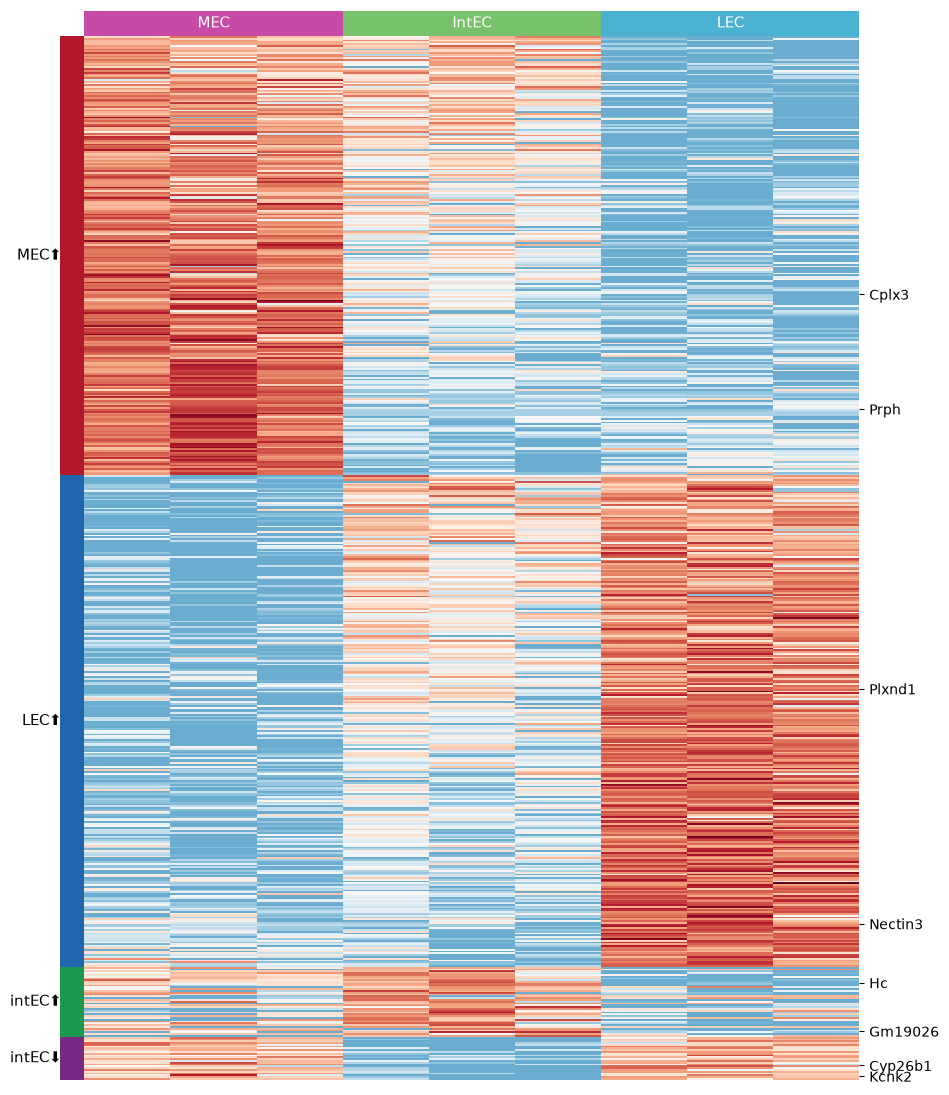

In [ ]:

row_colors = deseq_results.loc[gene_order, "category"].map(CLASS_COLORS).to_numpy()
col_colors = [REGION_COLORS[SAMPLE_REGION[v]] for v in ["V7","V8","V9","V1","V2","V3","V4","V5","V6"]]

expression_heatmap = sns.clustermap(
    grapher, cmap="RdBu_r", vmin=-1, vmax=2, center=0,
    row_cluster=False, col_cluster=False,
    row_colors=row_colors, col_colors=col_colors,
    colors_ratio=(0.03, 0.023),
    yticklabels=False, xticklabels=False,
    figsize=(8.5, 11),
    cbar_pos=None,
    dendrogram_ratio=(0.001, 0.001),
    z_score=0
)

all_gene_labels = grapher.index


tick_positions = [i for i, label in enumerate(all_gene_labels) if label in EXAMPLE_GENES]
tick_labels = [all_gene_labels[i] for i in tick_positions]

expression_heatmap.ax_heatmap.set_yticks(tick_positions)
expression_heatmap.ax_heatmap.set_yticklabels(tick_labels)

expression_heatmap.ax_heatmap.set_ylabel("")


region_category_ordered = region_category.reindex(index=gene_order)
region_category_ordered_renamed = [x.replace("-enriched", "⬆︎  ") for x in region_category_ordered.to_list()]
region_category_ordered_renamed = [x.replace("-suppressed", "⬇︎  ") for x in region_category_ordered_renamed]



def block_centers(labels):
    """labels: list of names, in heatmap row order.
    Returns {name: middle_y} for each consecutive run of the same name."""
    centers = {}
    start = 0
    n = len(labels)
    for i in range(1, n + 1):
        if i == n or labels[i] != labels[start]:
            centers[labels[start]] = (start + i) / 2
            start = i
    return centers

row_centers = block_centers(region_category_ordered_renamed)  # your list of names, one per row

for category, y in row_centers.items():
    expression_heatmap.ax_row_colors.text(
        0.5, y, category,
        ha="right", va="center", fontsize=11, rotation=0, color = "black",
        clip_on=False
    )


column_names = list(REGION_COLORS.keys())
column_positions = [1.5, 4.5, 7.5]
for x, label in zip(column_positions, column_names):
    expression_heatmap.ax_col_colors.text(
        x, 0.5, label,
        ha="center", va="center", fontsize=11, rotation=0, color = "white"
    )

expression_heatmap.savefig("bulk_heatmap.svg")
print("Saved: bulk_heatmap.svg" )

# Expression comparison graphs + exmaples


In [ ]:

def compute_zscores(gene_ids):
    """Per-gene z-score across region means."""
    region_means_matrix = deseq_results.loc[gene_ids, ["mean_MEC", "mean_IntEC", "mean_LEC"]].to_numpy()
    return (region_means_matrix - region_means_matrix.mean(1, keepdims=True)) / (region_means_matrix.std(1, keepdims=True) + 1e-9)

def gene_id_list(gene_name_list):
    return deseq_results.index[deseq_results["gene_name"].isin(gene_name_list)].to_list()


category_row_specs = [
    ("MEC-enriched", gene_id_list(["Cplx3","Prph"])),
    ("LEC-enriched", gene_id_list(["Plxnd1","Nectin3"])),
    ("intEC-enriched", gene_id_list(["Hc", "Gm19026"])),
    ("intEC-suppressed", gene_id_list(["Kcnk2","Cyp26b1"])),
]


# category with n of genes in it, colour, genes in the category, example genes, category name
category_rows = []
for category, examples in category_row_specs:
    ids = region_category_ordered.index[region_category_ordered == category]
    category_rows.append(("%s\n(n=%d)" % (category, len(ids)), CLASS_COLORS[category], ids, examples, category))


In [ ]:

def get_padjs(gene_id, category_name):
    """Return the class-defining pairwise comparisons for a gene."""
    gene_row = deseq_results.loc[gene_id]
    if category_name == "MEC-enriched":
        return [("MEC","LEC", gene_row["padj_LECvMEC"]),
                ("IntEC","LEC", gene_row["padj_intECvLEC"])]
    elif category_name == "LEC-enriched":
        return [("LEC","MEC", gene_row["padj_LECvMEC"]),
                ("IntEC","MEC", gene_row["padj_intECvMEC"])]
    else:
        return [("IntEC","MEC", gene_row["padj_intECvMEC"]),
                ("IntEC","LEC", gene_row["padj_intECvLEC"])]

def pstar(p):
    if p < 0.001: return "***"
    elif p < 0.01: return "**"
    elif p < 0.05: return "*"
    else: return "ns"

def add_brackets(ax, region_vals, padjs, xpos_map, axis_max):
    """Draw significance brackets above the highest dot of the two regions being compared."""
    gap = axis_max * 0.10
    step = axis_max * 0.14
    for i, (region_a, region_b, padj_value) in enumerate(padjs):
        xa, xb = xpos_map[region_a], xpos_map[region_b]
        local_top = max(region_vals[region_a].max(), region_vals[region_b].max())
        y = local_top + gap + i * step
        ax.plot([xa,xa,xb,xb], [y-step*0.25, y, y, y-step*0.25],
                color="#333", lw=2, clip_on=False)
        ax.text((xa+xb)/2, y+step*0.05, pstar(padj_value),
                ha="center", va="bottom", fontsize=8.5, color="#333")


region_xlabels = ["MEC", "IntEC", "LEC"]
region_xpos_map = {"MEC":0, "IntEC":1, "LEC":2}
region_xpos = list(region_xpos_map.values())




Gene-expression classes along the medial–intermediate–lateral axis
left: aggregate (thin=one gene; bold=mean; band=±SD); right: example genes
brackets: DESeq2 Benjamini and Hochberg-adjusted p-values (* p<0.05  ** p<0.01  *** p<0.001)
                    padj_intECvMEC  padj_intECvLEC  padj_LECvMEC
gene_id                                                         
ENSMUSG00000022656           0.750           0.000         0.000
ENSMUSG00000023484           0.000           0.886         0.000
ENSMUSG00000026874           0.078           0.000         0.000
ENSMUSG00000030123           0.000           0.000         0.000
ENSMUSG00000037624           0.000           0.000         0.939
ENSMUSG00000039714           0.000           0.000         0.000
ENSMUSG00000063415           0.000           0.000         0.000
ENSMUSG00000103845           0.006           0.019         0.970
Saved: FIG_gene_classes.svg


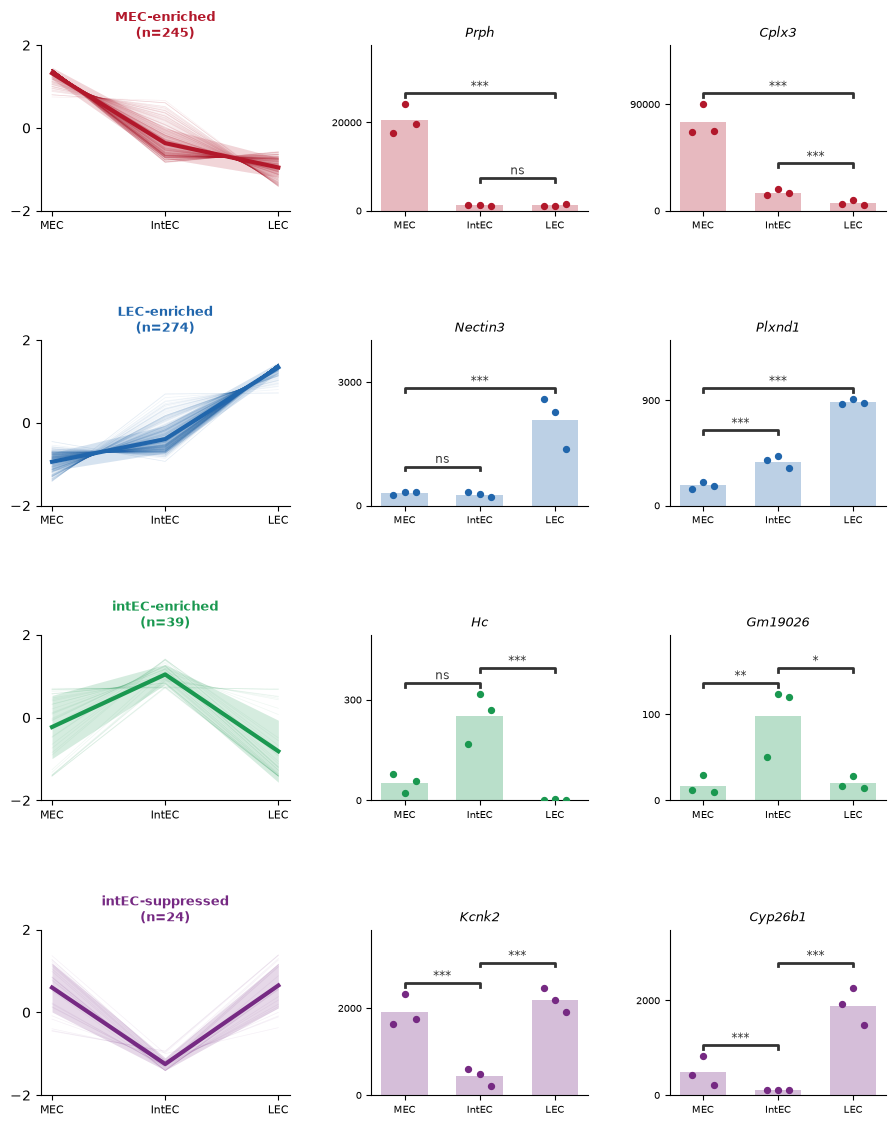

In [ ]:
fig = plt.figure(figsize=(9.5, 12.5))
grid_spec  = gridspec.GridSpec(
    4, 3, figure=fig,
    width_ratios=[1.15, 1, 1],
    hspace=0.78, wspace=0.36,
    left=0.09, right=0.98, top=0.90, bottom=0.06)


for row_idx, (name, colour, all_genes, example_genes, category) in enumerate(category_rows):
    ax = fig.add_subplot(grid_spec[row_idx, 0])
    all_genes = list(all_genes)
    zscore_matrix = compute_zscores(all_genes)

    # plot individual genes
    for i in range(len(all_genes)):
        ax.plot(region_xpos, zscore_matrix[i], color=colour, alpha=0.07, lw=0.5, zorder=1)

    # plot the mean per region of each gene
    ax.plot(region_xpos, zscore_matrix.mean(0), color=colour, lw=3.0, zorder=4)

    # shadow the +-sd of the mean
    ax.fill_between(region_xpos,
                    zscore_matrix.mean(0) - zscore_matrix.std(0),
                    zscore_matrix.mean(0) + zscore_matrix.std(0),
                    color=colour, alpha=0.18, lw=0)

    
    ax.set_xticks(region_xpos); ax.set_xticklabels(region_xlabels, fontsize=8)
    ax.set_yticks([-2,0,2]); ax.set_ylim(-2, 2)
    ax.set_title(name, fontsize=9.5, color=colour, fontweight="bold")
    hide_top_right(ax)

    # add example gene plots
    for example_idx, gene_id in enumerate([gene for gene in example_genes if gene is not None]):
        example_ax = fig.add_subplot(grid_spec[row_idx, example_idx+1])

        region_means = {r: deseq_results.loc[gene_id, f"mean_{r}"] for r in region_xlabels}
        region_vals = {}
        for xi, region_label in zip(region_xpos, region_xlabels):
            vals = normalized_counts.loc[gene_id, REGION_SAMPLE_IDS[region_label]].astype(float).to_numpy()
            region_vals[region_label] = vals
            example_ax.bar(xi, region_means[region_label], width=0.62, color=colour, alpha=0.30, zorder=1)
            example_ax.scatter(xi + np.array([-0.15,0,0.15]), vals, s=18, color=colour, zorder=3)


        max_val = max(v.max() for v in region_vals.values())
        example_ax.set_ylim(0, max_val*(1.55))

        padjs = get_padjs(gene_id, category)
        add_brackets(example_ax, region_vals, padjs, region_xpos_map, max_val)

        magnitude = 10 ** math.floor(math.log10(max(max_val, 1)))
        ytop = round(max_val / magnitude) * magnitude
        if ytop == 0: ytop = round(max_val, 1)
        example_ax.set_yticks([0, ytop])
        example_ax.tick_params(labelsize=7)

        example_ax.set_xticks(region_xpos)
        example_ax.set_xticklabels(region_xlabels, fontsize=7.5)
        hide_top_right(example_ax)

        gene_display_name = str(deseq_results.loc[gene_id, "gene_name"])
        example_ax.set_title(gene_display_name, fontsize=9, fontstyle="italic")
      

print(
    "Gene-expression classes along the medial–intermediate–lateral axis\n"
    "left: aggregate (thin=one gene; bold=mean; band=±SD); right: example genes\n"
    "brackets: DESeq2 Benjamini and Hochberg-adjusted p-values (* p<0.05  ** p<0.01  *** p<0.001)")

print(deseq_results.loc[deseq_results["gene_name"].isin(EXAMPLE_GENES),['padj_intECvMEC',  'padj_intECvLEC', 'padj_LECvMEC']].round(3))

fig.savefig("FIG_gene_classes.svg", dpi=160, bbox_inches="tight")
print(f"Saved: FIG_gene_classes.svg")